# Visits without a triage acuity score

**Contents**

- [Data](#Data)
- [Counts](#Counts)
- [Characteristics](#Characteristics)
  - [Table S3 — analysis sample vs excluded visits](#Table-S3)
- [All MIMIC-IV-ED visits](#All-MIMIC-IV-ED-visits)
  - [Table S4 — avoidable visit categories, analysis sample vs every raw visit](#Table-S4)
- [Missing data](#Missing-data)
  - [Figure 1 — co-missingness of acuity, age and discharge diagnosis](#Figure-1)
  - [Figure 2 — triage missingness patterns](#Figure-2)
  - [Table 3 — missingness by acuity status](#Table-3)
  - [Figure S2 — missingness heatmap: paper variables (A) and triage variables (B)](#Figure-S2)
  - [Table 4 — visits with no vital signs](#Table-4)

Three sections, everything read from the data build's two outputs (`ed_join_cc.parquet` and `ed_no_diagnosis.parquet`); no raw MIMIC files are read and no algorithm logic is re-implemented here.

- The data build (`MIMICED/1_mimic_data.ipynb`) carries the 380 visits with no discharge diagnosis through the entire pipeline and writes them to `ed_no_diagnosis.parquet` with every column the pipeline can compute, including the Resources and Triage-Acuity flags. Only the Diagnosis flag is NA for them (nothing to classify).
- Characteristics: the analysis sample (417,723 visits) against all 7,364 excluded visits, with patient-clustered differences (Table S3). The difference column with its CI carries the evidence; there is no separate test column.
- All MIMIC-IV-ED visits: the three algorithms applied to every raw visit (425,087), compared with the analysis sample by avoidable-visit category (Table S4). A flag that is missing prevents counting a visit as unflagged (Diagnosis for the 380 visits with no diagnosis; Triage-Acuity for the visits with no acuity score). The columns are nested, so the table gives percentage-point differences without CIs.
- Missing data, focused on triage acuity: Figure 1, co-missingness of acuity, age and discharge diagnosis across all 425,087 visits; Figure 2, which triage fields go missing together; Table 3 and Figure S2, what else is missing among acuity-missing against acuity-recorded visits (panel A the variables reported in the paper, panel B the other triage variables, which shows acuity is rarely missing on its own); Table 4, visits with no vital signs at all, by acuity status.

Only Tables S3 and S4 and Figure S2 are exported (`R1_acuity_table_S3.docx`, `R1_acuity_table_S4.docx`, `R1_acuity_figure_S2.*`); the other figures and tables display in the notebook only.

In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(arrow, geepack, gt, gtsummary, knitr, naniar, patchwork, tidyverse)

# cluster-aware CI helpers shared by the analysis notebooks
source("ci_helpers.R")

Loading required package: pacman



# Data

In [2]:
analysis_cols <- c("subject_id", "stay_id", "intime", "acuity", "age", "gender",
                   "race", "pain", "disposition", "length_of_stay",
                   "nyu", "res", "acuity_out")

ed_data <- read_parquet("../MIMICED/ed_join_cc.parquet", col_select = all_of(analysis_cols))

# the visits the data build drops for having no discharge diagnosis, carried
# through the same pipeline; their Diagnosis flag is NA (nothing to classify)
no_diagnosis <- read_parquet("../MIMICED/ed_no_diagnosis.parquet", col_select = all_of(analysis_cols))

# Counts

In [3]:
eligible <- ed_data |>
  filter(!is.na(acuity) & !is.na(age) & !is.na(race))

removed <- ed_data |>
  filter(is.na(acuity) | is.na(age))

no_acuity <- ed_data |>
  filter(is.na(acuity))

excluded <- bind_rows(removed, no_diagnosis)

n <- list(
  raw          = nrow(ed_data) + nrow(no_diagnosis),
  diagnosed    = nrow(ed_data),
  no_diagnosis = nrow(no_diagnosis),
  no_acuity    = nrow(no_acuity),
  no_age       = sum(is.na(ed_data$age) & !is.na(ed_data$acuity)),
  removed      = nrow(removed),
  excluded     = nrow(excluded),
  excluded_pat = n_distinct(excluded$subject_id),
  eligible     = nrow(eligible)
)

str(n)

List of 9
 $ raw         : int 425087
 $ diagnosed   : int 424707
 $ no_diagnosis: int 380
 $ no_acuity   : int 6934
 $ no_age      : int 50
 $ removed     : int 6984
 $ excluded    : int 7364
 $ excluded_pat: int 7134
 $ eligible    : int 417723


- `raw` — every ED visit in MIMIC-IV-ED v2.2
- `diagnosed` — visits with a discharge diagnosis
- `no_diagnosis` — visits the data build sets aside for having no discharge diagnosis
- `no_acuity` — acuity missing
- `no_age` — age missing
- `removed` — no_acuity and no_age combined
- `excluded` — every visit outside the analysis sample: removed plus no_diagnosis
- `excluded_pat` — patients behind the excluded visits; some also have a visit in the analysis sample
- `eligible` — the analysis sample: visits without missing data

## Check

In [4]:
checks <- tibble(
  check = c("Raw ED visits", "Visits with a discharge diagnosis", "No discharge diagnosis",
            "No triage acuity score", "No age recorded", "Removed visits", "Excluded visits",
            "Patients with an excluded visit", "Analysis sample"),
  observed = c(n$raw, n$diagnosed, n$no_diagnosis, n$no_acuity, n$no_age,
               n$removed, n$excluded, n$excluded_pat, n$eligible),
  expected = c(425087L, 424707L, 380L, 6934L, 50L, 6984L, 7364L, 7134L, 417723L)
) |>
  mutate(result = if_else(observed == expected, "PASS", "FAIL"))

checks |>
  print(n = 10)

stopifnot(all(checks$result == "PASS"))
stopifnot(n$no_acuity + n$no_age == n$removed)
stopifnot(n$diagnosed + n$no_diagnosis == n$raw)
stopifnot(n$removed + n$no_diagnosis == n$excluded)
stopifnot(n$eligible + n$excluded == n$raw)

# A tibble: 9 × 4
  check                             observed expected result
  <chr>                                <int>    <int> <chr> 
1 Raw ED visits                       425087   425087 PASS  
2 Visits with a discharge diagnosis   424707   424707 PASS  
3 No discharge diagnosis                 380      380 PASS  
4 No triage acuity score                6934     6934 PASS  
5 No age recorded                         50       50 PASS  
6 Removed visits                        6984     6984 PASS  
7 Excluded visits                       7364     7364 PASS  
8 Patients with an excluded visit       7134     7134 PASS  
9 Analysis sample                     417723   417723 PASS  


# Characteristics

In [5]:
table_vars <- function(data, collapse_race = FALSE) {
  data |>
    transmute(
      group,
      subject_id,
      age,
      gender = case_when(
        gender == "M" ~ "Male",
        gender == "F" ~ "Female"
      ),
      # collapse_race gives the five groups the main analysis reports;
      # the default keeps the full breakdown
      race = if (collapse_race) {
        case_when(
          str_detect(race, "WHITE") ~ "White",
          str_detect(race, "BLACK") ~ "Black",
          str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
          str_detect(race, "ASIAN") ~ "Asian",
          TRUE ~ "Other"
        )
      } else {
        case_when(
          str_detect(race, "WHITE") ~ "White",
          str_detect(race, "BLACK") ~ "Black",
          str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
          str_detect(race, "ASIAN") ~ "Asian",
          race == "OTHER" ~ "Other",
          race == "UNKNOWN" ~ "Unknown",
          race == "UNABLE TO OBTAIN" ~ "Unable to obtain",
          race == "PATIENT DECLINED TO ANSWER" ~ "Declined to answer",
          race == "PORTUGUESE" ~ "Portuguese",
          race == "SOUTH AMERICAN" ~ "South American",
          race == "AMERICAN INDIAN/ALASKA NATIVE" ~ "American Indian/Alaska Native",
          race == "NATIVE HAWAIIAN OR OTHER PACIFIC ISLANDER" ~ "Native Hawaiian/Pacific Islander",
          race == "MULTIPLE RACE/ETHNICITY" ~ "Multiple race/ethnicity",
          TRUE ~ str_to_sentence(race)
        )
      },
      pain = as.integer(pain),
      length_of_stay,
      disposition = case_when(
        disposition == "HOME" ~ "Home",
        disposition == "ADMITTED" ~ "Admitted",
        disposition == "EXPIRED" ~ "Died in the ED",
        TRUE ~ "Other"
      )
    ) |>
    mutate(race = fct_relevel(fct_infreq(race), "White", "Black", "Hispanic/Latino", "Asian"))
}

comparison_table <- function(data, show_missing = TRUE) {
  # keep only the labels and digit rules for variables this table actually has
  in_data <- function(rules) rules[map_lgl(rules, \(f) all.vars(f)[1] %in% names(data))]

  data |>
    tbl_summary(
      by = group,
      include = -any_of("subject_id"),
      type = all_continuous() ~ "continuous2",
      label = in_data(list(
        age ~ "Age (years)",
        gender ~ "Gender",
        race ~ "Self-reported race",
        pain ~ "Pain score (0-10)",
        length_of_stay ~ "Length of stay (minutes)",
        disposition ~ "Discharge disposition"
      )),
      statistic = list(
        all_continuous() ~ "{mean} ({sd})",
        all_categorical() ~ "{n} ({p}%)"
      ),
      digits = in_data(list(
        age ~ 1,
        pain ~ 1,
        length_of_stay ~ 0
      )),
      missing = if (show_missing) "ifany" else "no",
      missing_text = "Not recorded"
    ) |>
    bold_labels()
}

fmt_p <- function(p) if (p < 0.001) "p < 0.001" else sprintf("p = %.3f", p)

row_differences <- function(data, include_missing = TRUE) {
  fmt <- function(est, lo, hi, dp) {
    sprintf(paste0("%+.", dp, "f [%.", dp, "f, %.", dp, "f]"), est, lo, hi)
  }

  # cluster-robust difference between the two group levels (see ci_helpers.R);
  # the GEE coefficient is level 2 minus level 1, so the sign is flipped to
  # keep the table's first-minus-second convention
  diff_cells <- function(y, dp, scale = 1) {
    d <- gee_diff_ci(y, data$group, data$subject_id)
    list(
      difference = fmt(-d[["est"]] * scale, -d[["hi"]] * scale, -d[["lo"]] * scale, dp),
      test = sprintf("z = %.1f, %s", -d[["z"]], fmt_p(d[["p"]]))
    )
  }

  cont_rows <- function(v, dp) {
    cells <- diff_cells(data[[v]], dp)
    tibble(variable = v, label = "Mean (SD)", difference = cells$difference, test = cells$test)
  }

  miss_rows <- function(v) {
    cells <- diff_cells(is.na(data[[v]]), 1, scale = 100)
    tibble(variable = v, label = "Not recorded", difference = cells$difference, test = cells$test)
  }

  cat_rows <- function(v) {
    levels <- sort(unique(as.character(data[[v]][!is.na(data[[v]])])))
    map(levels, \(l) {
      cells <- diff_cells(data[[v]] == l, 1, scale = 100)
      tibble(variable = v, label = l, difference = cells$difference, test = cells$test)
    }) |>
      list_rbind()
  }

  bind_rows(
    cont_rows("age", 1),
    if ("pain" %in% names(data)) cont_rows("pain", 1),
    if (include_missing && "pain" %in% names(data)) miss_rows("pain"),
    cont_rows("length_of_stay", 0),
    if (include_missing) miss_rows("length_of_stay"),
    cat_rows("gender"),
    cat_rows("race"),
    cat_rows("disposition")
  )
}

add_row_differences <- function(x, data, include_missing = TRUE) {
  x |>
    modify_table_body(\(.x) .x |>
      left_join(row_differences(data, include_missing), by = c("variable", "label")) |>
      mutate(across(c(difference, test), \(v) replace_na(v, "")))) |>
    modify_header(difference = "**Difference (95% CI)**", test = "**Test**")
}

kable_summary <- function(x) {
  tbl <- x |>
    as_tibble() |>
    rename_with(\(nm) nm |> str_remove_all("\\*\\*") |> str_replace_all("\\s*\\n\\s*", ", ")) |>
    mutate(across(everything(), \(v) replace_na(str_remove_all(v, "^__|__$"), "")))

  kable(tbl, align = c("l", rep("r", ncol(tbl) - 1)))
}


## Table S3

In [6]:
# Table S3: characteristics of the analysis sample vs the excluded visits

table_S3_data <- bind_rows(
    eligible |> mutate(group = "Analysis sample"),
    excluded |> mutate(group = "Excluded visits")
  ) |>
  mutate(group = factor(group, levels = c("Analysis sample", "Excluded visits"))) |>
  table_vars(collapse_race = TRUE)

table_S3 <- table_S3_data |>
  comparison_table(show_missing = FALSE) |>
  add_row_differences(table_S3_data, include_missing = FALSE) |>
  # the difference column carries the evidence; the test column repeats it
  modify_table_body(\(x) x |> select(-test))

table_S3 |>
  kable_summary()

table_S3 |>
  as_gt() |>
  tab_source_note("95% CIs on differences are cluster-robust at the patient level (GEE with robust sandwich standard errors).") |>
  gtsave(filename = "R1_acuity_table_S3.docx")



|Characteristic           | Analysis sample, N = 417,723| Excluded visits, N = 7,364|  Difference (95% CI)|
|:------------------------|----------------------------:|--------------------------:|--------------------:|
|Age (years)              |                             |                           |                     |
|Mean (SD)                |                  52.8 (20.6)|                54.2 (21.4)|    -1.3 [-1.8, -0.8]|
|Gender                   |                             |                           |                     |
|Female                   |                226,798 (54%)|                3,100 (42%)|   +12.2 [11.0, 13.4]|
|Male                     |                190,925 (46%)|                4,264 (58%)| -12.2 [-13.4, -11.0]|
|Self-reported race       |                             |                           |                     |
|White                    |                242,486 (58%)|                3,516 (48%)|    +10.3 [9.1, 11.5]|
|Black                    

# Potentially Avoidable ED visits

## Table S4

In [7]:
# Avoidable visit categories, analysis sample vs every raw visit; a flag the
# missing data prevents computing counts as 0 — Diagnosis for the 380 visits
# with no discharge diagnosis, Triage-Acuity where acuity is missing

avoidable_categories <- c(
  "100" = "Diagnosis only",
  "010" = "Resources only",
  "001" = "Triage-Acuity only",
  "110" = "Diagnosis + Resources",
  "011" = "Resources + Triage-Acuity",
  "101" = "Diagnosis + Triage-Acuity",
  "111" = "All three",
  "000" = "None"
)

count_categories <- function(data) {
  data |>
    count(code = paste0(nyu, res, acuity_out)) |>
    complete(code = names(avoidable_categories), fill = list(n = 0)) |>
    mutate(
      percentage = n / sum(n) * 100,
      value = sprintf("%.1f (%s)", percentage, format(n, big.mark = ",", trim = TRUE))
    ) |>
    select(code, n, percentage, value)
}

all_visits <- bind_rows(
  ed_data |> transmute(nyu, res, acuity_out = replace_na(acuity_out, 0)),
  no_diagnosis |> transmute(nyu = replace_na(nyu, 0), res, acuity_out = replace_na(acuity_out, 0))
)

stopifnot(nrow(all_visits) == n$raw)
stopifnot(!anyNA(all_visits))

table_S4 <- tibble(
    code = names(avoidable_categories),
    category = unname(avoidable_categories)
  ) |>
  left_join(
    count_categories(eligible) |> select(code, analysis = value, analysis_pc = percentage),
    by = "code"
  ) |>
  left_join(
    count_categories(all_visits) |> select(code, all = value, all_pc = percentage),
    by = "code"
  ) |>
  mutate(difference = sprintf("%+.1f", analysis_pc - all_pc)) |>
  select(category, analysis, all, difference)

names(table_S4) <- c(
  "Avoidable visit category",
  sprintf("Analysis sample, N = %s, %% (n)", format(n$eligible, big.mark = ",")),
  sprintf("All ED visits, N = %s, %% (n)", format(n$raw, big.mark = ",")),
  "Difference (percentage points)"
)

table_S4 |>
  kable(align = c("l", "r", "r", "r"))

table_S4 |>
  gt() |>
  tab_source_note("The two columns are nested (every analysis-sample visit is also among all ED visits), so no confidence interval is given. A flag the missing data prevents computing counts as 0; the Diagnosis algorithm cannot be applied to the 380 visits with no discharge diagnosis.") |>
  gtsave(filename = "R1_acuity_table_S4.docx")



|Avoidable visit category  | Analysis sample, N = 417,723, % (n)| All ED visits, N = 425,087, % (n)| Difference (percentage points)|
|:-------------------------|-----------------------------------:|---------------------------------:|------------------------------:|
|Diagnosis only            |                      24.3 (101,442)|                    23.9 (101,767)|                           +0.3|
|Resources only            |                       10.4 (43,498)|                     10.4 (44,321)|                           -0.0|
|Triage-Acuity only        |                         1.9 (8,092)|                       1.9 (8,114)|                           +0.0|
|Diagnosis + Resources     |                        8.4 (34,944)|                      8.3 (35,350)|                           +0.0|
|Resources + Triage-Acuity |                         1.7 (6,969)|                       1.6 (7,003)|                           +0.0|
|Diagnosis + Triage-Acuity |                         1.8 (7,608)|  

# Missing data

### Figure 1

Of the 380 visits with no discharge diagnosis, 53 also lack a triage acuity score


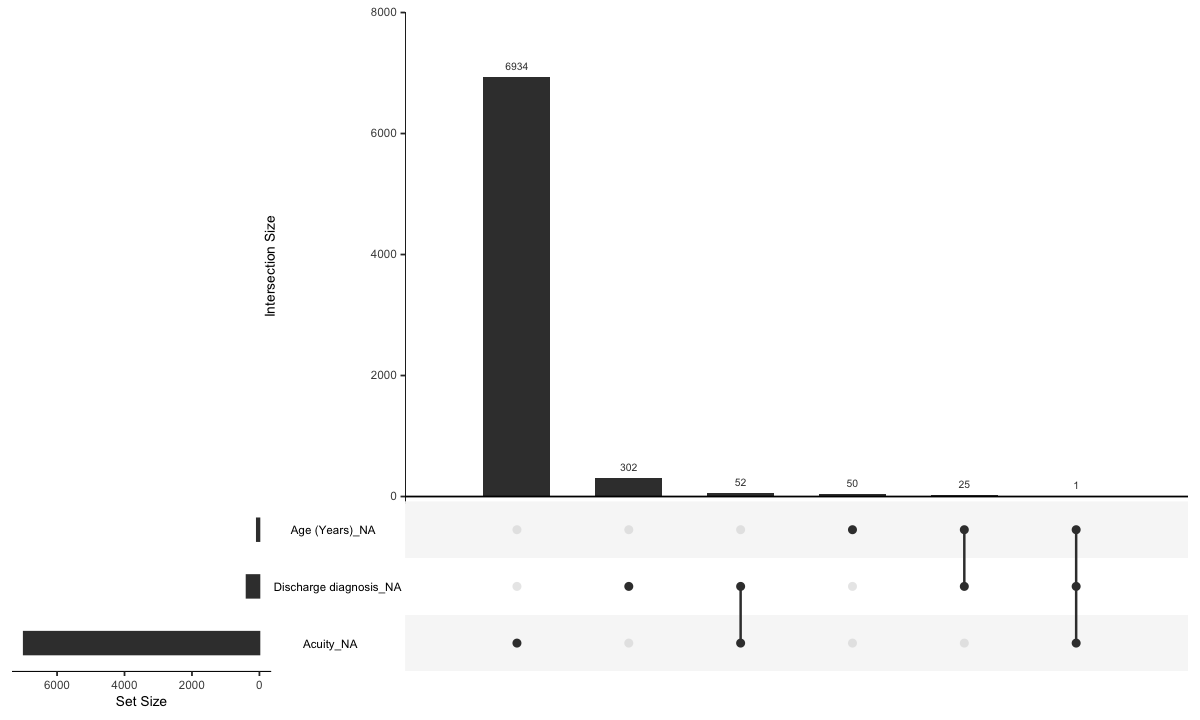

In [8]:
# Co-missingness 
# of acuity, age and discharge diagnosis across every raw ED
# visit, straight from the two build outputs

missing_flags <- bind_rows(
    ed_data |> transmute(diagnosis = 1, acuity, age),
    no_diagnosis |> transmute(diagnosis = NA_real_, acuity, age)
  ) |>
  transmute(
    `Discharge diagnosis` = diagnosis,
    Acuity                = if_else(!is.na(acuity), 1, NA_real_),
    `Age (Years)`         = if_else(!is.na(age), 1, NA_real_)
  )

n_nodiag_noacuity <- missing_flags |>
  filter(is.na(`Discharge diagnosis`) & is.na(Acuity)) |>
  nrow()

cat(sprintf(
  "Of the %s visits with no discharge diagnosis, %s also lack a triage acuity score\n",
  format(n$no_diagnosis, big.mark = ","), format(n_nodiag_noacuity, big.mark = ",")
))

options(repr.plot.width = 10, repr.plot.height = 6)

suppressWarnings(gg_miss_upset(missing_flags, nsets = 3))

### Figure 2

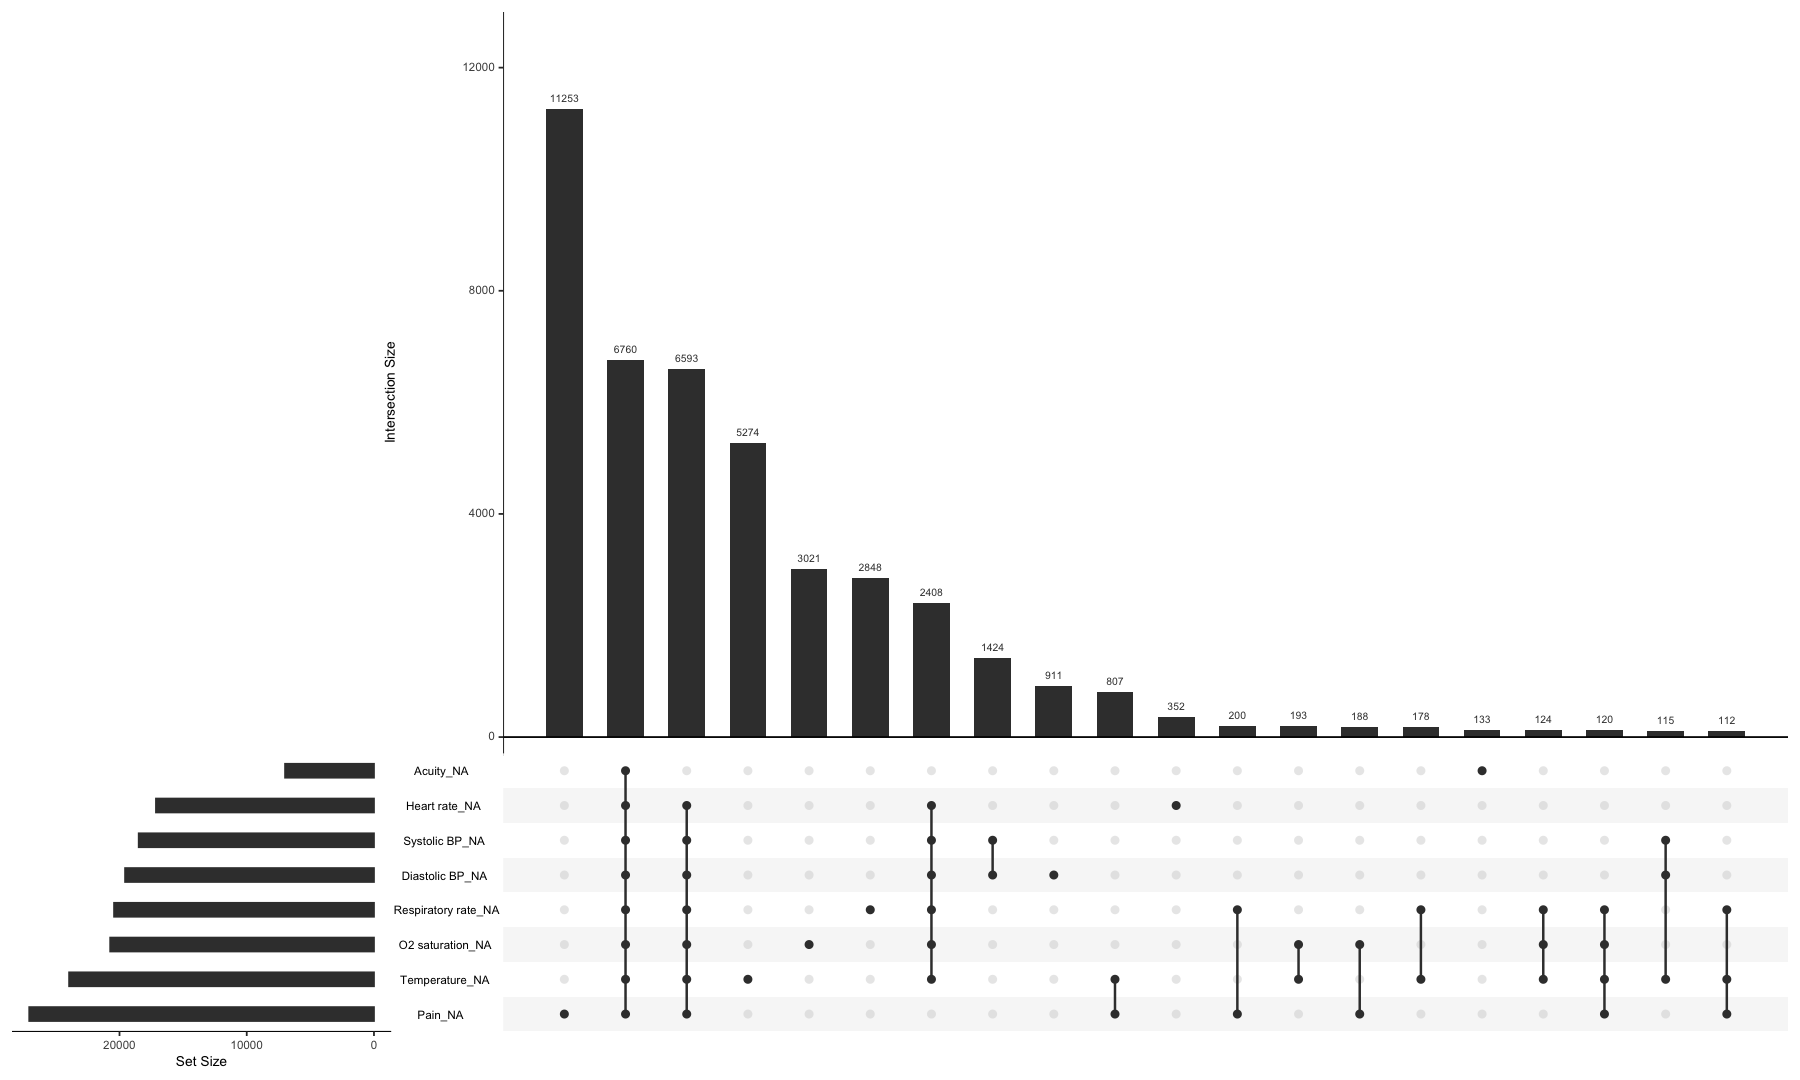

In [9]:
# Triage missingness combinations, every raw visit

triage_fields <- c(
  "Temperature"      = "temperature",
  "Heart rate"       = "heartrate",
  "Respiratory rate" = "resprate",
  "O2 saturation"    = "o2sat",
  "Systolic BP"      = "sbp",
  "Diastolic BP"     = "dbp",
  "Pain"             = "pain",
  "Acuity"           = "acuity",
  "Chief complaint"  = "chiefcomplaint"
)

triage_cols <- c("subject_id", "intime", "temperature", "heartrate", "resprate",
                 "o2sat", "sbp", "dbp", "pain", "acuity", "chiefcomplaint")

ed_triage <- bind_rows(
  read_parquet("../MIMICED/ed_join_cc.parquet", col_select = all_of(triage_cols)),
  read_parquet("../MIMICED/ed_no_diagnosis.parquet", col_select = all_of(triage_cols))
)

triage_all <- ed_triage |>
  select(all_of(triage_fields))

options(repr.plot.width = 15, repr.plot.height = 9)

triage_all |>
  select(-`Chief complaint`) |>
  gg_miss_upset(nsets = length(triage_fields) - 1, nintersects = 20)

### Table 3

In [10]:
# Missingness by acuity status; medications and rhythm count as missing when
# none were dispensed or recorded

raw_paths <- c(
  pyxis     = "../../../mimic-iv-ed-2.2/ed/pyxis.csv.gz",
  vitalsign = "../../../mimic-iv-ed-2.2/ed/vitalsign.csv.gz"
)

if (!all(file.exists(raw_paths))) {
  stop(paste("The following required file is missing:\n",
             paste(raw_paths[!file.exists(raw_paths)], collapse = "\n"),
             "\nSee README for more information."))
}

meds <- read_csv(raw_paths["pyxis"], col_select = c(stay_id), show_col_types = FALSE) |>
  distinct(stay_id) |>
  mutate(medications = "Dispensed")

rhythms <- read_csv(raw_paths["vitalsign"], col_select = c(stay_id, rhythm), show_col_types = FALSE) |>
  filter(!is.na(rhythm)) |>
  distinct(stay_id) |>
  mutate(rhythm = "Recorded")

acuity_split_fields <- c(
  "Temperature"        = "temperature",
  "Heart rate"         = "heartrate",
  "Respiratory rate"   = "resprate",
  "O2 saturation"      = "o2sat",
  "Systolic BP"        = "sbp",
  "Diastolic BP"       = "dbp",
  "Pain"               = "pain",
  "Chief complaint"    = "chiefcomplaint",
  "Age (Years)"        = "age",
  "Gender"             = "gender",
  "Self-reported Race" = "race",
  "Length of stay"     = "length_of_stay",
  "Disposition"        = "disposition",
  "Common Diagnoses"   = "icd_chapter",
  "Common Complaints"  = "cluster",
  "Medications"        = "medications",
  "Heart rhythm"       = "rhythm"
)

ed_acuity_split <- read_parquet(
    "../MIMICED/ed_join_cc.parquet",
    col_select = c(subject_id, stay_id, intime, acuity, temperature, heartrate, resprate, o2sat, sbp, dbp,
                   pain, chiefcomplaint, age, gender, race, length_of_stay, disposition,
                   icd_chapter)
  ) |>
  left_join(
    read_parquet("../MIMICED/chiefcomp_clustered.parquet", col_select = c(stay_id, cluster)),
    by = "stay_id"
  ) |>
  left_join(meds, by = "stay_id") |>
  left_join(rhythms, by = "stay_id") |>
  mutate(acuity_group = if_else(is.na(acuity), "Missing acuity", "Acuity recorded"))

# visit-level indicators for the cluster-robust differences below; column
# names carry the display labels so the table's variable column matches
split_ind <- ed_acuity_split |>
  select(all_of(acuity_split_fields), acuity_group, subject_id) |>
  mutate(acuity_group = factor(acuity_group, levels = c("Acuity recorded", "Missing acuity")))

missing_by_acuity <- ed_acuity_split |>
  select(all_of(acuity_split_fields), acuity_group) |>
  group_by(acuity_group) |>
  miss_var_summary() |>
  ungroup() |>
  mutate(n_miss = as.integer(n_miss), pct_miss = as.numeric(pct_miss))

variable_order <- missing_by_acuity |>
  filter(acuity_group == "Missing acuity") |>
  arrange(desc(pct_miss)) |>
  pull(variable)

group_ns <- ed_acuity_split |>
  count(acuity_group) |>
  deframe()

n_missing_grp  <- unname(group_ns["Missing acuity"])
n_recorded_grp <- unname(group_ns["Acuity recorded"])

table_3 <- missing_by_acuity |>
  filter(acuity_group == "Missing acuity") |>
  select(variable, miss_n = n_miss, miss_pct = pct_miss) |>
  left_join(
    missing_by_acuity |>
      filter(acuity_group == "Acuity recorded") |>
      select(variable, rec_n = n_miss, rec_pct = pct_miss),
    by = "variable"
  ) |>
  mutate(
    missing_acuity  = sprintf("%.1f (%s)", miss_pct, format(miss_n, big.mark = ",", trim = TRUE)),
    acuity_recorded = sprintf("%.1f (%s)", rec_pct, format(rec_n, big.mark = ",", trim = TRUE)),
    gee = map(variable, \(v) {
      y <- is.na(split_ind[[v]])
      if (any(y)) gee_diff_ci(y, split_ind$acuity_group, split_ind$subject_id)
    }),
    difference = map_chr(gee, \(d) {
      if (is.null(d)) "" else sprintf("%+.1f [%.1f, %.1f]", d[["est"]] * 100, d[["lo"]] * 100, d[["hi"]] * 100)
    }),
    test = map_chr(gee, \(d) {
      if (is.null(d)) "" else sprintf("z = %.1f, %s", d[["z"]], fmt_p(d[["p"]]))
    }),
    variable = factor(variable, levels = variable_order)
  ) |>
  arrange(variable) |>
  mutate(variable = as.character(variable)) |>
  select(variable, missing_acuity, acuity_recorded, difference, test)

names(table_3) <- c(
  "Variable",
  sprintf("Missing acuity, N = %s, %% (n)", format(n_missing_grp, big.mark = ",")),
  sprintf("Acuity recorded, N = %s, %% (n)", format(n_recorded_grp, big.mark = ",")),
  "Difference (95% CI)",
  "Test"
)

table_3 |>
  kable(align = c("l", "r", "r", "r", "r"))



|Variable           | Missing acuity, N = 6,934, % (n)| Acuity recorded, N = 417,773, % (n)| Difference (95% CI)|                 Test|
|:------------------|--------------------------------:|-----------------------------------:|-------------------:|--------------------:|
|Temperature        |                     97.5 (6,764)|                        4.1 (17,116)|  +93.5 [93.1, 93.8]| z = 496.0, p < 0.001|
|Diastolic BP       |                     97.4 (6,756)|                        3.0 (12,730)|  +94.4 [94.0, 94.8]| z = 491.8, p < 0.001|
|Respiratory rate   |                     97.4 (6,755)|                        3.3 (13,598)|  +94.2 [93.8, 94.5]| z = 489.4, p < 0.001|
|Systolic BP        |                     97.4 (6,755)|                        2.8 (11,661)|  +94.6 [94.3, 95.0]| z = 492.3, p < 0.001|
|O2 saturation      |                     97.4 (6,752)|                        3.3 (13,905)|  +94.0 [93.7, 94.4]| z = 484.2, p < 0.001|
|Heart rate         |                     97.3

### Figure S2

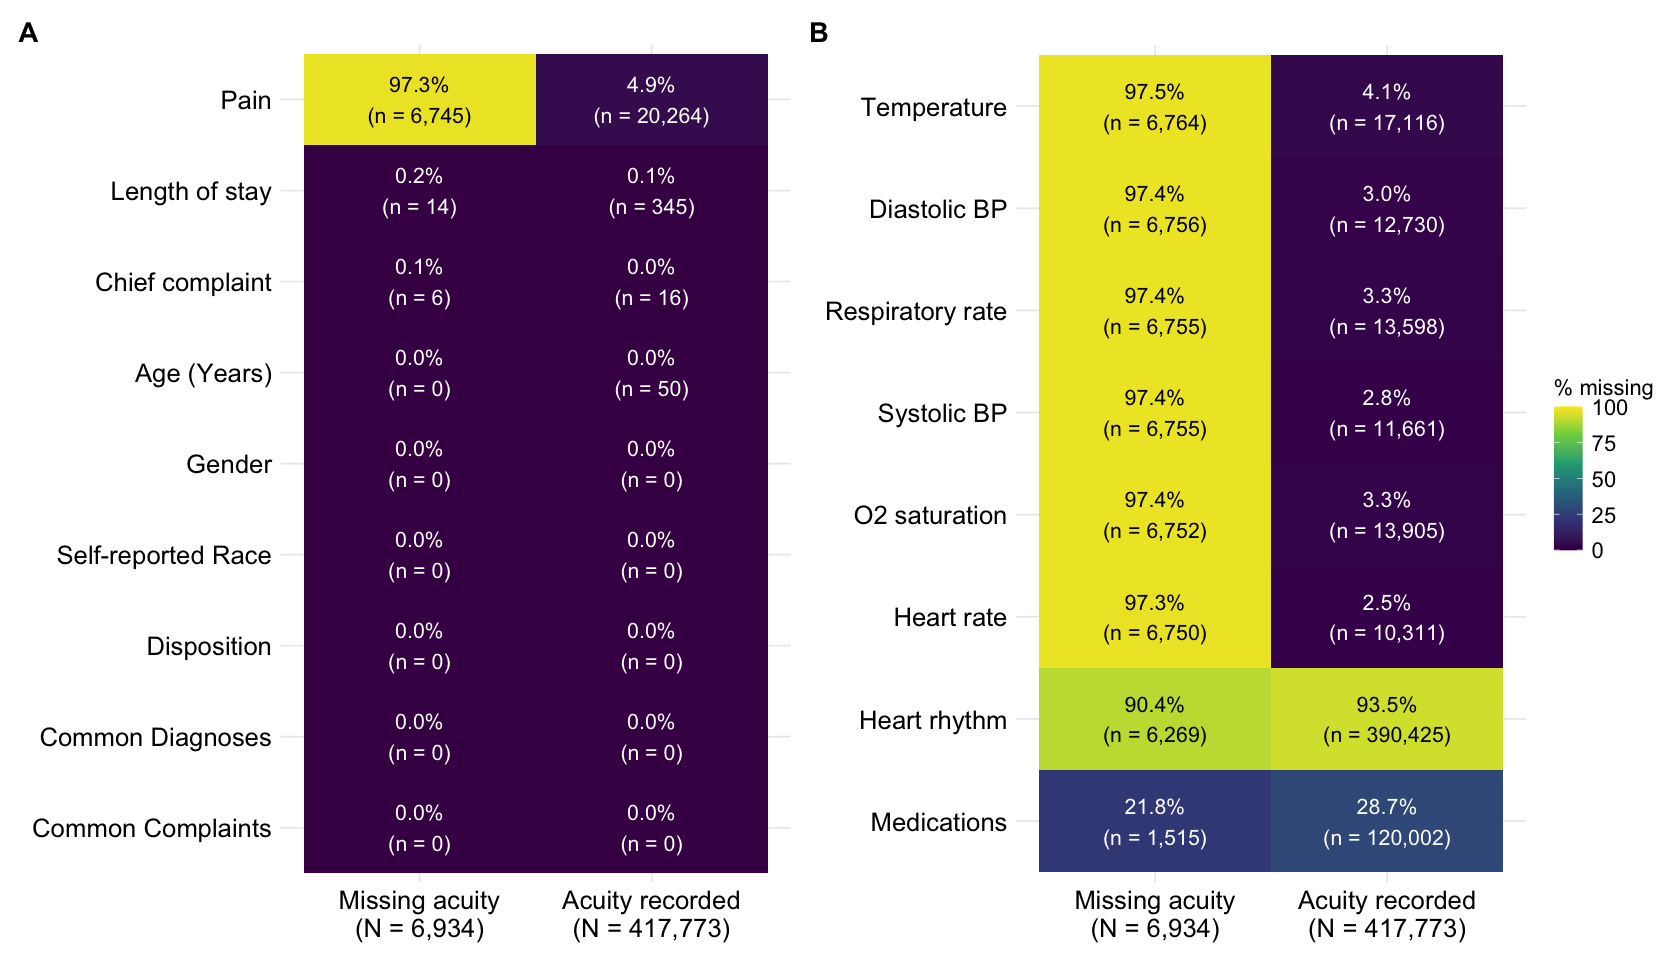

In [11]:
# % missing per variable by acuity status: panel A carries the variables
# reported in the paper, panel B the triage variables that are not study
# outcomes but show that acuity is rarely the only thing missing

# the paper's variables, including chief complaint, which the paper reports
# after clustering ("Common Complaints" is its processed form)
paper_vars <- c("Age (Years)", "Gender", "Self-reported Race", "Pain", "Chief complaint",
                "Length of stay", "Disposition", "Common Diagnoses", "Common Complaints")

group_labels <- sprintf(
  "%s\n(N = %s)", c("Missing acuity", "Acuity recorded"),
  format(group_ns[c("Missing acuity", "Acuity recorded")], big.mark = ",", trim = TRUE)
)

heat_data <- missing_by_acuity |>
  mutate(
    variable = factor(variable, levels = rev(variable_order)),
    acuity_group = factor(
      sprintf("%s\n(N = %s)", acuity_group,
              format(group_ns[acuity_group], big.mark = ",", trim = TRUE)),
      levels = group_labels
    ),
    label = sprintf("%.1f%%\n(n = %s)", pct_miss, format(n_miss, big.mark = ",", trim = TRUE))
  )

heat_panel <- function(vars) {
  heat_data |>
    filter(variable %in% vars) |>
    ggplot(aes(x = acuity_group, y = variable, fill = pct_miss)) +
    geom_tile() +
    geom_text(aes(colour = pct_miss < 60, label = label), size = 4.5) +
    scale_fill_viridis_c(limits = c(0, 100), name = "% missing") +
    scale_colour_manual(values = c(`FALSE` = "black", `TRUE` = "white"), guide = "none") +
    labs(x = NULL, y = NULL) +
    theme_minimal()
}

options(repr.plot.width = 14, repr.plot.height = 8)

Figure_S2 <- heat_panel(paper_vars) +
  heat_panel(setdiff(names(acuity_split_fields), paper_vars)) +
  plot_layout(guides = "collect") +
  plot_annotation(tag_levels = "A") &
  theme(
    plot.tag = element_text(size = rel(1.5), face = "bold"),
    axis.text = element_text(size = rel(1.4), colour = "black"),
    legend.text = element_text(size = rel(1.2)),
    legend.title = element_text(size = rel(1.2))
  )

ggsave("R1_acuity_figure_S2.png", plot = Figure_S2, device = "png", width = 14, height = 8, units = "in", dpi = 600)
ggsave("R1_acuity_figure_S2.svg", plot = Figure_S2, device = "svg", width = 14, height = 8, units = "in")
ggsave("R1_acuity_figure_S2.pdf", plot = Figure_S2, device = "pdf", width = 14, height = 8, units = "in")
Figure_S2

### Table 4

In [12]:
# Visits with no vitals recorded

vital_fields <- c("temperature", "heartrate", "resprate", "o2sat", "sbp", "dbp", "pain")

table_4_data <- read_parquet(
    "../MIMICED/ed_join_cc.parquet",
    col_select = c(subject_id, temperature, heartrate, resprate, o2sat, sbp, dbp, pain,
                   acuity, age, gender, race, disposition, length_of_stay, nyu, res)
  ) |>
  filter(if_all(all_of(vital_fields), is.na)) |>
  mutate(
    group = factor(
      if_else(is.na(acuity), "No acuity, no vitals", "Acuity, no vitals"),
      levels = c("Acuity, no vitals", "No acuity, no vitals")
    )
  ) |>
  table_vars() |>
  select(-pain)

table_4 <- table_4_data |>
  comparison_table() |>
  add_row_differences(table_4_data)

table_4 |>
  kable_summary()



|Characteristic                   | Acuity, no vitals, N = 6,579| No acuity, no vitals, N = 6,707| Difference (95% CI)|                 Test|
|:--------------------------------|----------------------------:|-------------------------------:|-------------------:|--------------------:|
|Age (years)                      |                             |                                |                    |                     |
|Mean (SD)                        |                  59.4 (21.1)|                     54.5 (21.4)|     +4.8 [4.1, 5.6]|  z = 12.7, p < 0.001|
|Gender                           |                             |                                |                    |                     |
|Female                           |                  2,912 (44%)|                     2,742 (41%)|     +3.4 [1.7, 5.1]|   z = 3.9, p < 0.001|
|Male                             |                  3,667 (56%)|                     3,965 (59%)|   -3.4 [-5.1, -1.7]|  z = -3.9, p < 0.001|
|Sel